# 04 — Reproduce results from saved weights (local GPU)

Rebuilds every number and figure for the report from the trained checkpoints:

1. Check saved runs and the preprocessing cache (rebuild cache if missing, verify fold split)
2. Probability maps for each fold's validation images (out-of-fold, OOF) and the test set
3. Post-processing tuned for Panoptic Quality on all 707 OOF images
4. Kaggle submission CSV (5-model ensemble)
5. Report tables: per-fold training, OOF summary, ablations, per-station / per-year PQ, pretrained vs scratch
6. Figures: training curves, qualitative examples
7. Inference speed, fp16 weight export

Run top to bottom. Steps that already have outputs on disk are skipped.

In [1]:
import os, sys, json, glob, time, subprocess
from pathlib import Path

ROOT  = Path(os.environ.get("FIL_ROOT", "C:/Users/kpatel528/fil"))
REPO  = ROOT / "solar-filament-seg"
os.environ.setdefault("FILAMENT_DATA", str(ROOT / "MAGFiLO_1.0_Kaggle_2026"))
CACHE = ROOT / "cache"
RUNS  = ROOT / "runs"
RES   = ROOT / "results"
RES.mkdir(parents=True, exist_ok=True)

EXPERIMENTS = {"r34": "ResNet-34 U-Net, ImageNet-pretrained", "r34s": "ResNet-34 U-Net, from scratch"}
FOLDS = [0, 1, 2, 3, 4]
WORKERS = 16

os.chdir(REPO); sys.path.insert(0, str(REPO))
PY = sys.executable
def run(cmd):
    """Run a repo script with this kernel's Python and stream its output."""
    print(">>", cmd, flush=True)
    r = subprocess.run(f'"{PY}" -m {cmd}', shell=True)
    if r.returncode: raise RuntimeError(f"failed: {cmd}")

print("FILAMENT_DATA =", os.environ["FILAMENT_DATA"], "| exists:", Path(os.environ["FILAMENT_DATA"]).exists())
import torch; print("torch", torch.__version__, "| CUDA:", torch.cuda.is_available(),
                    torch.cuda.get_device_name(0) if torch.cuda.is_available() else "")

FILAMENT_DATA = C:\Users\kpatel528\fil\MAGFiLO_1.0_Kaggle_2026 | exists: True
torch 2.6.0+cu124 | CUDA: True NVIDIA GeForce RTX 4090


## 1. Inventory: which runs, weights and outputs exist

In [2]:
import pandas as pd
rows = []
for exp in EXPERIMENTS:
    for f in FOLDS:
        d = RUNS / f"{exp}_f{f}"
        rows.append(dict(exp=exp, fold=f, dir_exists=d.exists(),
                         best_pt=(d / "best.pt").exists(), config=(d / "config.json").exists(),
                         log=(d / "log.csv").exists(),
                         val_probs=len(glob.glob(str(d / "val_probs" / "*.npy"))),
                         test_probs=len(glob.glob(str(d / "test_probs" / "*.npy")))))
inv = pd.DataFrame(rows)
print(inv.to_string(index=False))
print("\ncache meta.csv exists:", (CACHE / "meta.csv").exists())
AVAILABLE = [e for e in EXPERIMENTS if inv[(inv.exp == e)].best_pt.all() and inv[(inv.exp == e)].config.all()]
print("experiments with all 5 folds trained:", AVAILABLE)

 exp  fold  dir_exists  best_pt  config  log  val_probs  test_probs
 r34     0        True     True    True True        139         180
 r34     1        True     True    True True        142         180
 r34     2        True     True    True True        142         180
 r34     3        True     True    True True        139         180
 r34     4        True     True    True True        145         180
r34s     0        True     True    True True        139         180
r34s     1        True     True    True True        142         180
r34s     2        True     True    True True        142         180
r34s     3        True     True    True True        139         180
r34s     4        True     True    True True        145         180

cache meta.csv exists: True
experiments with all 5 folds trained: ['r34', 'r34s']


## 2. Preprocessing cache (rebuilt only if missing)

The fold split is made deterministically from the file list, so rebuilding on the same machine gives the same folds.
The check below compares fold sizes with the validation sizes each training run logged — if they differ, the
out-of-fold numbers would be invalid.

In [3]:
if not (CACHE / "meta.csv").exists():
    run(f"src.build_cache --out {CACHE.as_posix()} --workers {WORKERS}")
meta = pd.read_csv(CACHE / "meta.csv", keep_default_na=False)
fold_sizes = meta[meta.split == "train"].groupby("fold").size().to_dict()
print("fold sizes in cache:", fold_sizes)

for exp in AVAILABLE:
    for f in FOLDS:
        n = len(glob.glob(str(RUNS / f"{exp}_f{f}" / "val_probs" / "*.npy")))
        if n:
            stems_done = {Path(x).stem for x in glob.glob(str(RUNS / f"{exp}_f{f}" / "val_probs" / "*.npy"))}
            in_fold = set(meta[(meta.split == "train") & (meta.fold == f)].stem)
            if not stems_done <= in_fold:
                print(f"WARNING {exp}_f{f}: val maps exist for images outside fold {f} — split mismatch!")
            elif n < fold_sizes[f]:
                print(f"note {exp}_f{f}: {n}/{fold_sizes[f]} val maps (incomplete earlier run; will be redone)")
meta[meta.split == "train"][["stem", "fold"]].to_csv(REPO / "folds.csv", index=False)
print("disk outliers:", int(meta.disk_outlier.sum()) if "disk_outlier" in meta else "n/a")

fold sizes in cache: {0: 139, 1: 142, 2: 142, 3: 139, 4: 145}
disk outliers: 0


## 3. (Optional) Train the from-scratch model — ~1.5 h on an RTX 4090
Set `TRAIN_SCRATCH = True` once; skip if `r34s` already shows all folds trained.

In [4]:
TRAIN_SCRATCH = False
if TRAIN_SCRATCH:
    for f in FOLDS:
        out = RUNS / f"r34s_f{f}"
        if not (out / "best.pt").exists():
            run(f"src.train --cache {CACHE.as_posix()} --fold {f} --encoder resnet34 --pretrained 0 "
                f"--epochs 30 --batch 8 --workers 10 --val_every 3 --out {out.as_posix()}")
    AVAILABLE = [e for e in EXPERIMENTS if all((RUNS / f"{e}_f{f}" / "best.pt").exists() for f in FOLDS)]
print("available:", AVAILABLE)

available: ['r34', 'r34s']


## 4. Probability maps (validation = out-of-fold, and test)

In [5]:
for exp in AVAILABLE:
    for f in FOLDS:
        d = RUNS / f"{exp}_f{f}"
        n_val = len(glob.glob(str(d / "val_probs" / "*.npy")))
        if n_val != fold_sizes[f]:
            run(f"src.predict --run {d.as_posix()} --split val --cache {CACHE.as_posix()}")
        if len(glob.glob(str(d / "test_probs" / "*.npy"))) != (meta.split == "test").sum():
            run(f"src.predict --run {d.as_posix()} --split test --cache {CACHE.as_posix()}")
print("done")

done


## 5. Tune post-processing on all OOF images, then write the submission

In [6]:
SUMMARY = {}
for exp in AVAILABLE:
    out = RES / exp; out.mkdir(exist_ok=True)
    runs = " ".join((RUNS / f"{exp}_f{f}").as_posix() for f in FOLDS)
    if not (out / "postproc.json").exists():
        run(f"src.tune --runs {runs} --cache {CACHE.as_posix()} --out {(out / 'postproc.json').as_posix()} --workers {WORKERS}")
    if not (out / "submission.csv").exists():
        run(f"src.make_submission --runs {runs} --params {(out / 'postproc.json').as_posix()} "
            f"--cache {CACHE.as_posix()} --out {(out / 'submission.csv').as_posix()} --workers {WORKERS}")
    SUMMARY[exp] = json.load(open(out / "postproc.json"))
    print(exp, SUMMARY[exp]["params"], SUMMARY[exp]["oof"])

r34 {'thr': 0.2, 'close_px': 3, 'min_area': 250, 'min_score': 0.8} {'pq_mean_per_image': 0.4006, 'pq_global': 0.4091, 'sq_global': 0.6672, 'dice_mean': 0.6519, 'tp': 3125.7, 'fp': 1869.3, 'fn': 2075.8, 'one_to_many': 373, 'many_to_one': 199}
r34s {'thr': 0.3, 'close_px': 3, 'min_area': 400, 'min_score': 0.8} {'pq_mean_per_image': 0.3805, 'pq_global': 0.3896, 'sq_global': 0.6663, 'dice_mean': 0.6501, 'tp': 3169.3, 'fp': 2470.7, 'fn': 2032.2, 'one_to_many': 500, 'many_to_one': 210}


## 6. Report tables

In [7]:
tab = []
for exp in AVAILABLE:
    for f in FOLDS:
        log = pd.read_csv(RUNS / f"{exp}_f{f}" / "log.csv").rename(columns={"val_soft_dice": "val_dice"})
        tab.append(dict(model=EXPERIMENTS[exp], fold=f, best_val_dice=log.val_dice.max(),
                        best_epoch=int(log.loc[log.val_dice.idxmax(), "epoch"]),
                        train_min=round(log.sec.sum() / 60, 1)))
fold_tab = pd.DataFrame(tab)
print(fold_tab.pivot(index="fold", columns="model", values="best_val_dice").round(4))
print(fold_tab.groupby("model")[["best_val_dice", "train_min"]].agg(["mean", "std"]).round(4))

model  ResNet-34 U-Net, ImageNet-pretrained  ResNet-34 U-Net, from scratch
fold                                                                      
0                                    0.6750                         0.6736
1                                    0.6666                         0.6609
2                                    0.6826                         0.6640
3                                    0.6735                         0.6622
4                                    0.7030                         0.6867
                                     best_val_dice         train_min        
                                              mean     std      mean     std
model                                                                       
ResNet-34 U-Net, ImageNet-pretrained        0.6801  0.0140     17.96  0.0894
ResNet-34 U-Net, from scratch               0.6695  0.0108     18.40  0.0000


In [8]:
KAGGLE = {"classical": ("0.08", "0.08"), "r34_single": ("0.32", "0.33"), "r34": ("0.33", "0.35")}
main = [dict(method="Human vs human (inter-annotator)", oof_pq=0.345, oof_sq=0.636, kaggle_private="-", kaggle_public="-"),
        dict(method="Classical black-hat baseline", oof_pq=None, oof_sq=None,
             kaggle_private=KAGGLE["classical"][0], kaggle_public=KAGGLE["classical"][1]),
        dict(method="ResNet-34 U-Net pretrained, single fold-0 model", oof_pq=None, oof_sq=None,
             kaggle_private=KAGGLE["r34_single"][0], kaggle_public=KAGGLE["r34_single"][1])]
for exp in AVAILABLE:
    o = SUMMARY[exp]["oof"]
    k = KAGGLE.get(exp, ("?", "?"))
    main.append(dict(method=EXPERIMENTS[exp] + ", 5-fold ensemble", oof_pq=o["pq_global"], oof_sq=o["sq_global"],
                     oof_dice=o["dice_mean"], tp=o["tp"], fp=o["fp"], fn=o["fn"],
                     one_to_many=o["one_to_many"], many_to_one=o["many_to_one"],
                     kaggle_private=k[0], kaggle_public=k[1]))
main_tab = pd.DataFrame(main); main_tab.to_csv(RES / "main_table.csv", index=False)
print(main_tab.round(4).to_string(index=False))

                                               method  oof_pq  oof_sq kaggle_private kaggle_public  oof_dice     tp     fp     fn  one_to_many  many_to_one
                     Human vs human (inter-annotator)  0.3450  0.6360              -             -       NaN    NaN    NaN    NaN          NaN          NaN
                         Classical black-hat baseline     NaN     NaN           0.08          0.08       NaN    NaN    NaN    NaN          NaN          NaN
      ResNet-34 U-Net pretrained, single fold-0 model     NaN     NaN           0.32          0.33       NaN    NaN    NaN    NaN          NaN          NaN
ResNet-34 U-Net, ImageNet-pretrained, 5-fold ensemble  0.4091  0.6672           0.33          0.35    0.6519 3125.7 1869.3 2075.8        373.0        199.0
       ResNet-34 U-Net, from scratch, 5-fold ensemble  0.3896  0.6663              ?             ?    0.6501 3169.3 2470.7 2032.2        500.0        210.0


In [9]:
for exp in AVAILABLE:
    g = pd.read_csv(RES / exp / "tune_grid.csv")
    best = g.iloc[0]
    def best_where(mask): 
        r = g[mask].iloc[0]; return round(r.pq, 4), dict(thr=r.thr, close_px=int(r.close_px), min_area=int(r.min_area), min_score=r.min_score)
    abl = {
        "full (tuned)": (round(best.pq, 4), dict(thr=best.thr, close_px=int(best.close_px), min_area=int(best.min_area), min_score=best.min_score)),
        "no confidence filter (min_score=0)": best_where(g.min_score == 0),
        "no gap closing (close_px=0)": best_where(g.close_px == 0),
        "no size filter (min_area=100)": best_where(g.min_area == g.min_area.min()),
        "fixed thr=0.5 only": best_where(g.thr == 0.5),
    }
    print(f"\n{EXPERIMENTS[exp]}")
    for k, (pq, p) in abl.items(): print(f"  {k:38s} PQ={pq:.4f}  {p}")


ResNet-34 U-Net, ImageNet-pretrained
  full (tuned)                           PQ=0.4091  {'thr': np.float64(0.2), 'close_px': 3, 'min_area': 250, 'min_score': np.float64(0.8)}
  no confidence filter (min_score=0)     PQ=0.3981  {'thr': np.float64(0.5), 'close_px': 3, 'min_area': 400, 'min_score': np.float64(0.0)}
  no gap closing (close_px=0)            PQ=0.4060  {'thr': np.float64(0.2), 'close_px': 0, 'min_area': 250, 'min_score': np.float64(0.8)}
  no size filter (min_area=100)          PQ=0.4090  {'thr': np.float64(0.2), 'close_px': 3, 'min_area': 100, 'min_score': np.float64(0.8)}
  fixed thr=0.5 only                     PQ=0.4038  {'thr': np.float64(0.5), 'close_px': 3, 'min_area': 400, 'min_score': np.float64(0.8)}

ResNet-34 U-Net, from scratch
  full (tuned)                           PQ=0.3896  {'thr': np.float64(0.3), 'close_px': 3, 'min_area': 400, 'min_score': np.float64(0.8)}
  no confidence filter (min_score=0)     PQ=0.3825  {'thr': np.float64(0.5), 'close_px': 3, 'min_

In [10]:
best_exp = max(AVAILABLE, key=lambda e: SUMMARY[e]["oof"]["pq_global"])
oof = pd.read_csv(RES / best_exp / "oof_per_image.csv")
per_img = oof.groupby("image").agg(pq=("pq", "mean"), n_gt=("n_gt", "mean")).reset_index()
per_img = per_img.merge(meta[["stem", "station", "year"]], left_on="image", right_on="stem")
print("by station:\n", per_img.groupby("station").pq.agg(["mean", "count"]).round(3))
print("\nby year:\n", per_img.groupby("year").agg(pq=("pq", "mean"), images=("pq", "size"), filaments_per_img=("n_gt", "mean")).round(3))
per_img.to_csv(RES / "oof_per_image_meta.csv", index=False)

by station:
           mean  count
station              
B        0.385    118
C        0.389    125
L        0.408    127
M        0.393    125
T        0.416    110
U        0.417    102

by year:
          pq  images  filaments_per_img
year                                  
2011  0.405      86              7.300
2012  0.407      92              8.728
2013  0.401     101              9.373
2014  0.425     102              9.899
2015  0.414      86              9.095
2016  0.397      80              6.806
2017  0.407      71              3.310
2018  0.422      26              1.468
2019  0.286      14              1.810
2020  0.277       9              2.056
2021  0.314      28              3.232
2022  0.378      12              6.681


## 7. Figures

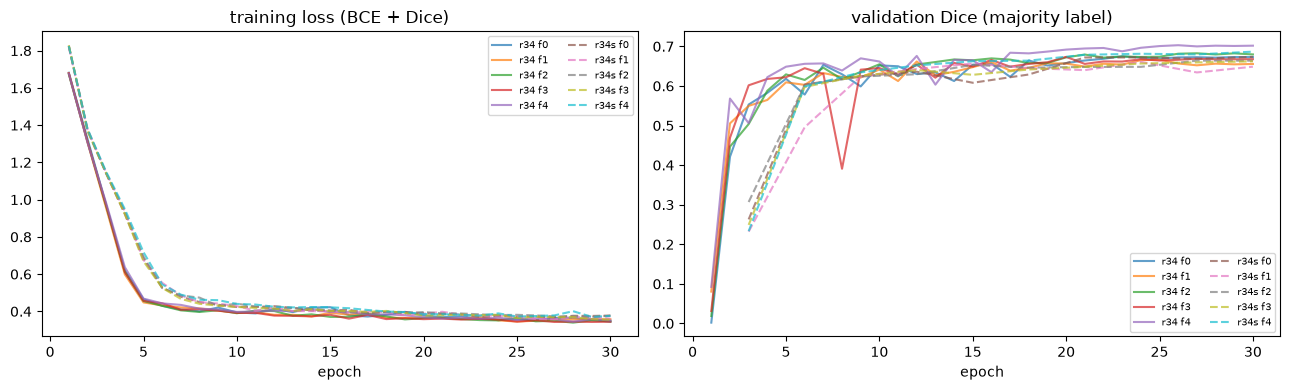

In [11]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for exp in AVAILABLE:
    for f in FOLDS:
        log = pd.read_csv(RUNS / f"{exp}_f{f}" / "log.csv").rename(columns={"val_soft_dice": "val_dice"})
        v = log.dropna(subset=["val_dice"])
        ls = "-" if exp == "r34" else "--"
        ax[0].plot(log.epoch, log.loss, ls, alpha=.7, label=f"{exp} f{f}")
        ax[1].plot(v.epoch, v.val_dice, ls, alpha=.7, label=f"{exp} f{f}")
ax[0].set_title("training loss (BCE + Dice)"); ax[1].set_title("validation Dice (majority label)")
for a in ax: a.set_xlabel("epoch"); a.legend(fontsize=7, ncol=2)
plt.tight_layout(); plt.savefig(RES / "fig_training_curves.png", dpi=150); plt.show()

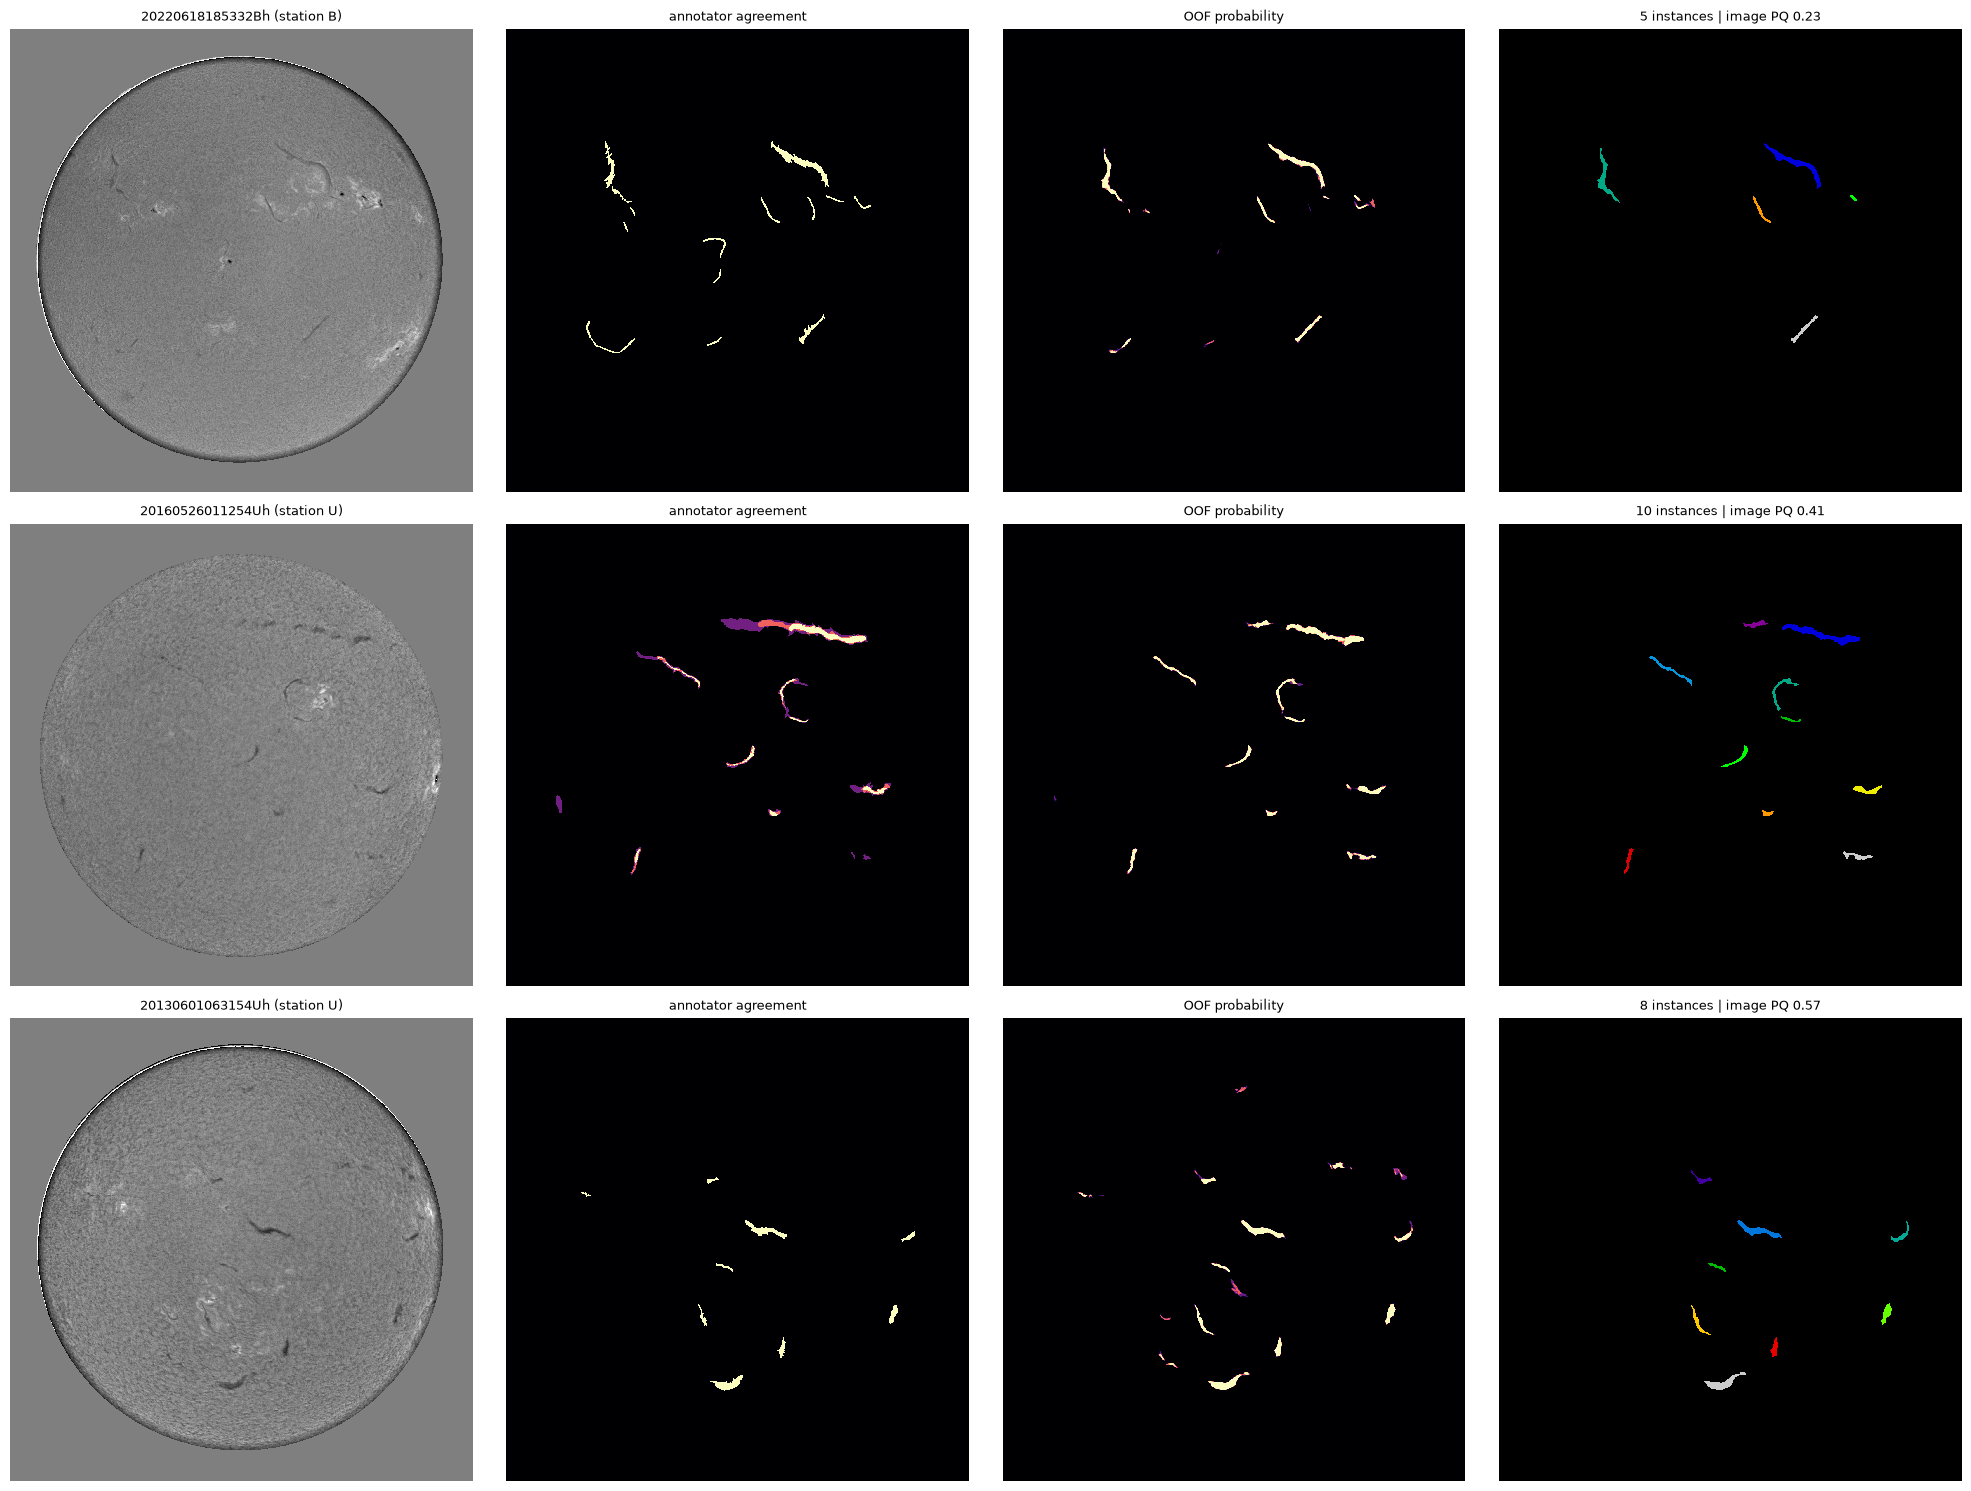

In [12]:
import cv2, numpy as np
from src.preprocess import radius_map
from src.postprocess import instances_from_response
from src.masks import rle_to_mask
params = SUMMARY[best_exp]["params"]
fold_of = meta.set_index("stem").fold
pick = per_img.sort_values("pq")
examples = [pick.iloc[len(pick) // 10].image, pick.iloc[len(pick) // 2].image, pick.iloc[-len(pick) // 10].image]
fig, axes = plt.subplots(3, 4, figsize=(20, 15))
for i, s in enumerate(examples):
    r = meta.set_index("stem").loc[s]
    img = cv2.imread(r.img_path, 0); soft = cv2.imread(r.soft_path, 0) / 255.0
    p = np.load(RUNS / f"{best_exp}_f{int(r.fold)}" / "val_probs" / f"{s}.npy").astype(np.float32)
    inst = instances_from_response(p, radius_map(r.cx, r.cy, r.r), **params)
    lab = np.zeros(img.shape, np.int32)
    for k, rle in enumerate(inst, 1): lab[rle_to_mask(rle)] = k
    pq = per_img.set_index("image").loc[s].pq
    for j, (im, t, cm) in enumerate([(img, f"{s} (station {r.station})", "gray"), (soft, "annotator agreement", "magma"),
                                     (p, "OOF probability", "magma"), (lab, f"{len(inst)} instances | image PQ {pq:.2f}", "nipy_spectral")]):
        axes[i, j].imshow(im, cmap=cm, interpolation="nearest"); axes[i, j].set_title(t, fontsize=9); axes[i, j].axis("off")
plt.tight_layout(); plt.savefig(RES / "fig_qualitative.png", dpi=120); plt.show()

## 8. Efficiency and weight export

In [13]:
from src.model import build_model
from src.infer import predict_full
cfg = json.load(open(RUNS / f"{best_exp}_f0" / "config.json"))
dev = "cuda" if torch.cuda.is_available() else "cpu"
sync = torch.cuda.synchronize if dev == "cuda" else (lambda: None)
model = build_model(cfg["encoder"], pretrained=False).to(dev)
sd = torch.load(RUNS / f"{best_exp}_f0" / "best.pt", map_location=dev)
model.load_state_dict({k: v.float() if v.is_floating_point() else v for k, v in sd.items()})
img = cv2.imread(meta[meta.split == "test"].iloc[0].img_path, 0)
for tta in (False, True):
    predict_full(model, img, dev, tta=tta); sync()
    t0 = time.time()
    for _ in range(10): predict_full(model, img, dev, tta=tta)
    sync()
    print(f"one model, 2048x2048, TTA={tta}: {(time.time() - t0) / 10 * 1000:.0f} ms/image")
print("parameters:", sum(p.numel() for p in model.parameters()) / 1e6, "M")

C:\Users\kpatel528\fil\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


one model, 2048x2048, TTA=False: 59 ms/image
one model, 2048x2048, TTA=True: 140 ms/image
parameters: 24.544088 M


In [14]:
for exp in AVAILABLE:
    runs = " ".join((RUNS / f"{exp}_f{f}").as_posix() for f in FOLDS)
    run(f"src.export_weights --runs {runs} --out {(REPO / 'weights').as_posix()}")

>> src.export_weights --runs C:/Users/kpatel528/fil/runs/r34_f0 C:/Users/kpatel528/fil/runs/r34_f1 C:/Users/kpatel528/fil/runs/r34_f2 C:/Users/kpatel528/fil/runs/r34_f3 C:/Users/kpatel528/fil/runs/r34_f4 --out C:/Users/kpatel528/fil/solar-filament-seg/weights
>> src.export_weights --runs C:/Users/kpatel528/fil/runs/r34s_f0 C:/Users/kpatel528/fil/runs/r34s_f1 C:/Users/kpatel528/fil/runs/r34s_f2 C:/Users/kpatel528/fil/runs/r34s_f3 C:/Users/kpatel528/fil/runs/r34s_f4 --out C:/Users/kpatel528/fil/solar-filament-seg/weights


## 9. Improvements inspired by the 10th-place solution (~35 min on an RTX 4090)

**9a. 8-view test-time augmentation**: average all 4 rotations x 2 flips instead of 3 flips.
**9b. Learned candidate scorer + PQ-aware selection**: generate overlapping candidates at several thresholds,
predict each candidate's expected matched IoU with LightGBM (cross-fitted by fold), keep the best non-overlapping
set whose predicted IoU exceeds tau (theory: tau ~ PQ/2).

In [15]:
for f in FOLDS:
    d = RUNS / f"r34_f{f}"
    if len(glob.glob(str(d / "val_probs8" / "*.npy"))) != fold_sizes[f]:
        run(f"src.predict --run {d.as_posix()} --split val --tta 8 --out_name val_probs8 --cache {CACHE.as_posix()}")
    if len(glob.glob(str(d / "test_probs8" / "*.npy"))) != (meta.split == "test").sum():
        run(f"src.predict --run {d.as_posix()} --split test --tta 8 --out_name test_probs8 --cache {CACHE.as_posix()}")
out = RES / "r34_tta8"; out.mkdir(exist_ok=True)
runs = " ".join((RUNS / f"r34_f{f}").as_posix() for f in FOLDS)
if not (out / "postproc.json").exists():
    run(f"src.tune --runs {runs} --cache {CACHE.as_posix()} --probs_name val_probs8 --out {(out / 'postproc.json').as_posix()} --workers {WORKERS}")
if not (out / "submission.csv").exists():
    run(f"src.make_submission --runs {runs} --params {(out / 'postproc.json').as_posix()} --probs_name test_probs8 "
        f"--cache {CACHE.as_posix()} --out {(out / 'submission.csv').as_posix()} --workers {WORKERS}")
SUMMARY["r34_tta8"] = json.load(open(out / "postproc.json"))
print("3-view TTA OOF PQ:", SUMMARY["r34"]["oof"]["pq_global"], "| 8-view TTA OOF PQ:", SUMMARY["r34_tta8"]["oof"]["pq_global"])

>> src.tune --runs C:/Users/kpatel528/fil/runs/r34_f0 C:/Users/kpatel528/fil/runs/r34_f1 C:/Users/kpatel528/fil/runs/r34_f2 C:/Users/kpatel528/fil/runs/r34_f3 C:/Users/kpatel528/fil/runs/r34_f4 --cache C:/Users/kpatel528/fil/cache --probs_name val_probs8 --out C:/Users/kpatel528/fil/results/r34_tta8/postproc.json --workers 16
>> src.make_submission --runs C:/Users/kpatel528/fil/runs/r34_f0 C:/Users/kpatel528/fil/runs/r34_f1 C:/Users/kpatel528/fil/runs/r34_f2 C:/Users/kpatel528/fil/runs/r34_f3 C:/Users/kpatel528/fil/runs/r34_f4 --params C:/Users/kpatel528/fil/results/r34_tta8/postproc.json --probs_name test_probs8 --cache C:/Users/kpatel528/fil/cache --out C:/Users/kpatel528/fil/results/r34_tta8/submission.csv --workers 16
3-view TTA OOF PQ: 0.4091 | 8-view TTA OOF PQ: 0.4152


In [17]:
best_maps = ("val_probs8", "test_probs8") if SUMMARY["r34_tta8"]["oof"]["pq_global"] > SUMMARY["r34"]["oof"]["pq_global"] \
            else ("val_probs", "test_probs")
out = RES / "r34_scorer"
if not (out / "scorer.json").exists():
    run(f"src.scorer --runs {runs} --cache {CACHE.as_posix()} --val_name {best_maps[0]} --test_name {best_maps[1]} "
        f"--out {out.as_posix()} --workers {WORKERS}")
sc = json.load(open(out / "scorer.json"))
print("maps:", best_maps, "| tau:", sc["tau"], "| OOF corr:", round(sc["corr"], 3))
print(pd.read_csv(out / "tau_grid.csv").to_string(index=False))
print(pd.read_csv(out / "feature_importance.csv", index_col=0).head(10).to_string())

>> src.scorer --runs C:/Users/kpatel528/fil/runs/r34_f0 C:/Users/kpatel528/fil/runs/r34_f1 C:/Users/kpatel528/fil/runs/r34_f2 C:/Users/kpatel528/fil/runs/r34_f3 C:/Users/kpatel528/fil/runs/r34_f4 --cache C:/Users/kpatel528/fil/cache --val_name val_probs8 --test_name test_probs8 --out C:/Users/kpatel528/fil/results/r34_scorer --workers 16
maps: ('val_probs8', 'test_probs8') | tau: 0.22 | OOF corr: 0.646
 tau  pq_mean_per_image  pq_global  sq_global  dice_mean     tp     fp     fn  one_to_many  many_to_one
0.22             0.4140     0.4240     0.6749     0.6600 3146.5 1670.5 2055.0          368          164
0.25             0.4126     0.4224     0.6753     0.6540 3053.8 1509.2 2147.7          330          159
0.20             0.4118     0.4224     0.6746     0.6610 3187.2 1791.8 2014.3          397          164
0.28             0.4121     0.4220     0.6760     0.6487 2975.8 1355.2 2225.7          290          157
0.30             0.4125     0.4219     0.6768     0.6455 2918.7 1244.3 228

In [18]:
imp = pd.DataFrame([
    dict(step="Pretrained 5-fold, 3-view TTA, tuned thresholds", oof_pq=SUMMARY["r34"]["oof"]["pq_global"], csv="results/r34/submission.csv"),
    dict(step="+ 8-view TTA", oof_pq=SUMMARY["r34_tta8"]["oof"]["pq_global"], csv="results/r34_tta8/submission.csv"),
    dict(step="+ learned scorer + PQ-aware selection", oof_pq=sc["oof"]["pq_global"], csv="results/r34_scorer/submission.csv"),
])
imp.to_csv(RES / "improvement_table.csv", index=False); print(imp.round(4).to_string(index=False))

                                           step  oof_pq                               csv
Pretrained 5-fold, 3-view TTA, tuned thresholds  0.4091        results/r34/submission.csv
                                   + 8-view TTA  0.4152   results/r34_tta8/submission.csv
          + learned scorer + PQ-aware selection  0.4240 results/r34_scorer/submission.csv
